In [46]:
#imports 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from pathlib import Path 

DATA_PATH = Path("..")/"data"
REPORTS_PATH = Path("..")/"reports"

raw = DATA_PATH/"raw"/"diabetes.csv" 

population = pd.read_csv(raw, index_col=0)
population.shape

(768, 8)

In [47]:
df.head()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,,,,,,,,
6,148,72,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
8,183,64,0,0,23.3,0.672,32,1
1,89,66,23,94,28.1,0.167,21,0
0,137,40,35,168,43.1,2.288,33,1


Part A - Glucose 

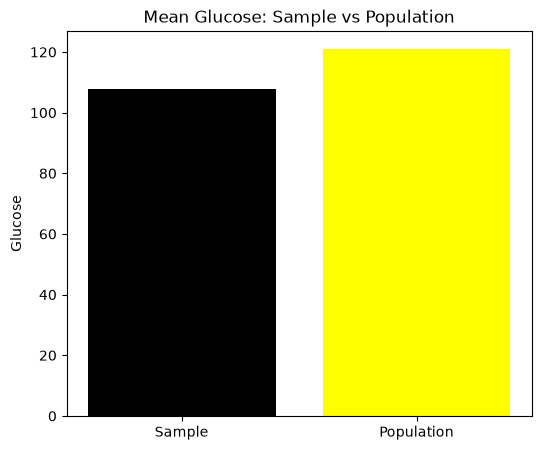

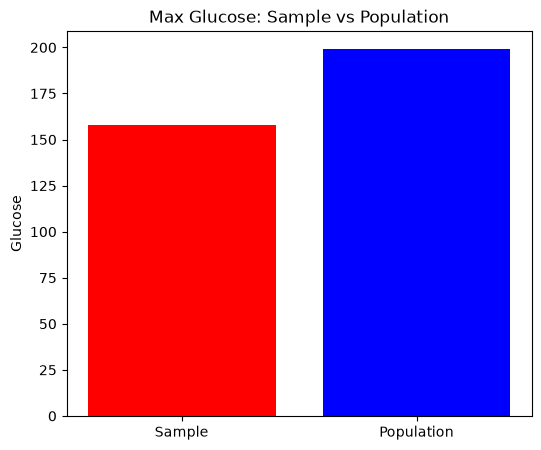

In [48]:
np.random.seed(24)

sample = population.sample(n=25, random_state = 24)

glucose_mean_sample = sample["Glucose"].mean()
glucose_max_sample = sample["Glucose"].max()


glucose_mean_population = population["Glucose"].mean()
glucose_max_population = population["Glucose"].max()

plt.figure(figsize=(6, 5))
plt.bar(["Sample", "Population"], [glucose_mean_sample, glucose_mean_population], color=["black", "yellow"])
plt.title("Mean Glucose: Sample vs Population")
plt.ylabel("Glucose")
plt.savefig(REPORTS_PATH / "glucose_mean.png", bbox_inches="tight")
plt.show()


plt.figure(figsize=(6, 5))
plt.bar(["Sample", "Population"], [glucose_max_sample, glucose_max_population], color=["red", "blue"])
plt.title("Max Glucose: Sample vs Population")
plt.ylabel("Glucose")
plt.savefig(REPORTS_PATH / "glucose_max.png", bbox_inches="tight")
plt.show()

Part B - BMI

98th percentile for BMI in Sample:  46.388
98th percentile for BMI in Population:  47.52599999999996


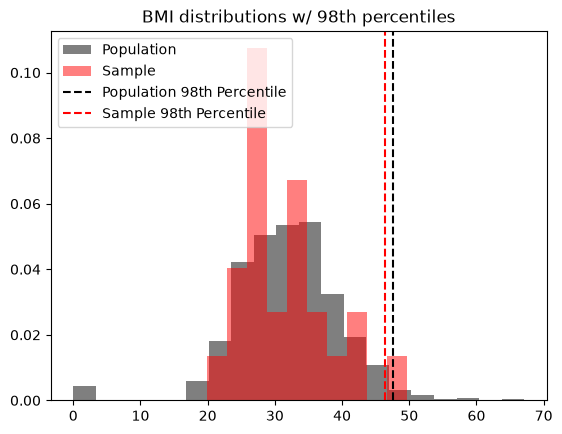

In [49]:
#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.quantile.html
sample_98 = sample["BMI"].quantile(0.98)
print("98th percentile for BMI in Sample: ", sample_98)

population_98 = population["BMI"].quantile(0.98)
print("98th percentile for BMI in Population: ", population_98)

plt.figure()
plt.hist(population["BMI"], color = "black", bins=20, alpha=0.5, density=True, label="Population")
plt.hist(sample["BMI"], color = "red", bins=10, alpha=0.5, density=True, label="Sample")
plt.axvline(population_98, color="black", linestyle="--", label="Population 98th Percentile")
plt.axvline(sample_98, color="red", linestyle="--", label="Sample 98th Percentile")
plt.legend()
plt.title("BMI distributions w/ 98th percentiles")
plt.savefig(REPORTS_PATH / "bmi_hist.png", bbox_inches="tight")
plt.show()

Part C - Bootstrap

                 Bootstrap  Population
Mean             69.107867   69.105469
Std Dev          19.193048   19.355807
98th Percentile  97.669640   99.320000


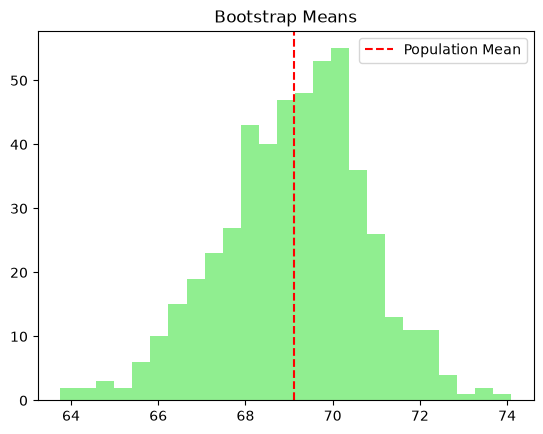

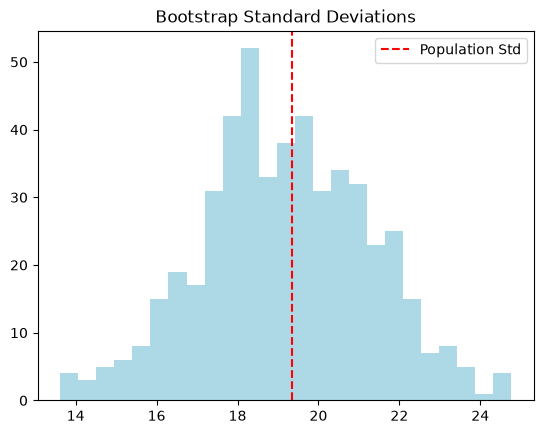

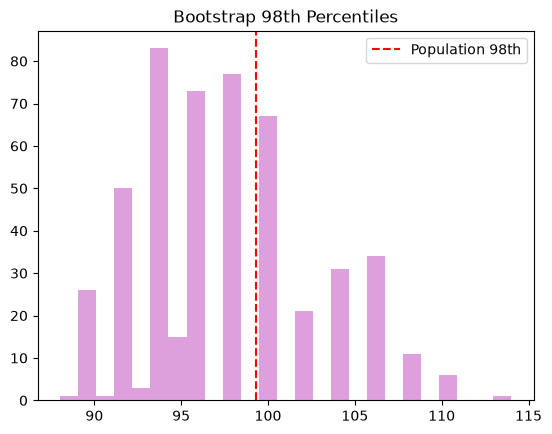

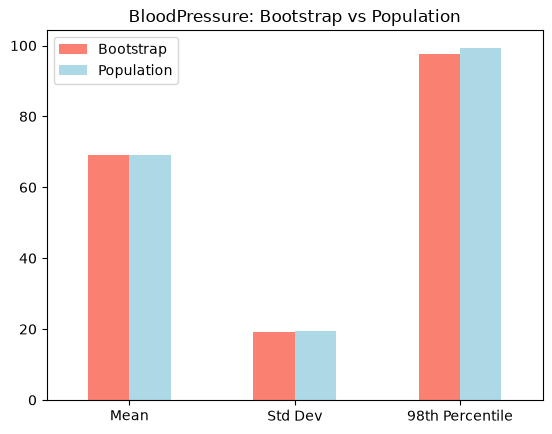

In [50]:
np.random.seed(24)

sample_number = 500
sample_size = 150

pop_BP_mean = population["BloodPressure"].mean()
pop_BP_std = population["BloodPressure"].std()
pop_BP_percentile_98 = population["BloodPressure"].quantile(0.98)

means = []
stds = []
percentile_98 = []

for i in range(sample_number):
    bootstrap = population["BloodPressure"].sample(n=sample_size, replace=True)

    means.append(bootstrap.mean())
    stds.append(bootstrap.std())
    percentile_98.append(bootstrap.quantile(0.98))

boostrap_mean = np.mean(means)
bootsrap_std = np.mean(stds)
bootstrap_98th_percentile = np.mean(percentile_98)

bloodpressure_results = pd.DataFrame({
    "Bootstrap": [boostrap_mean, bootsrap_std, bootstrap_98th_percentile],
    "Population": [pop_BP_mean, pop_BP_std, pop_BP_percentile_98]
}, index=["Mean", "Std Dev", "98th Percentile"])

print(bloodpressure_results)


plt.hist(means, bins=25, color="lightgreen")
plt.axvline(pop_BP_mean, color="red", linestyle="--", label="Population Mean")
plt.title("Bootstrap Means")
plt.legend()
plt.savefig(REPORTS_PATH / "bootstrap_means.png")
plt.show()

plt.hist(stds, bins=25, color="lightblue")
plt.axvline(pop_BP_std, color="red", linestyle="--", label="Population Std")
plt.title("Bootstrap Standard Deviations")
plt.legend()
plt.savefig(REPORTS_PATH / "bootstrap_stds.png")
plt.show()

plt.hist(percentile_98, bins=25, color="plum")
plt.axvline(pop_BP_percentile_98, color="red", linestyle="--", label="Population 98th")
plt.title("Bootstrap 98th Percentiles")
plt.legend()
plt.savefig(REPORTS_PATH / "bootstrap_p98.png")
plt.show()

bloodpressure_results.plot(kind="bar", color=["salmon", "lightblue"])
plt.title("BloodPressure: Bootstrap vs Population")
plt.xticks(rotation=0)
plt.savefig(REPORTS_PATH / "bootstrap_vs_population.png")
plt.show()

Reflection 
- The bootstrap mean and the standard deviation matached closely with the popuation mean  and standard deviaiton. The mean was only .002 higher for the bootstrap. The standard deveiton was about 0.16 higher in the population than it was in the bootstrap. The 98th percentile was the one with the biggest gap from the bootstrap and the population, the population having 99.32 and the boostap coming in at 97.67. Since the bootstrap is drawing from the random samples with repalcemnet this is a prediceted change that we are seeing. I think that many of the smapels might have missed the highest reading thus pulling down the 98th percentile for the bootstrap. This is not chnagin the data but it shows how the affect of repaeted sampling with replacement. 